# Лабораторна робота №4. Розрахунок нерекурсивних цифрових фільтрів

Варіант 23.

## Вихідні дані

Режекторний фільтр порядку N = 4, гранична частота f_g1 = 20 Гц, друга гранична частота f_g2 = f_g + 2n = 20 + 2·23 = 66 Гц (n це номер варіанту), частота дискретизації fₐ = 400 Гц, Tₐ = 1/fₐ = 0,0025 с. Фільтр симетричний (формула (4)): індекси k = −2…2, тобто 5 коефіцієнтів дають порядок 4.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

variant_number = 23
filter_order = 4
lower_cutoff_frequency = 20.0
upper_cutoff_frequency = lower_cutoff_frequency + 2 * variant_number  # fg2 = fg + 2n, n is the variant number
sampling_frequency = 400.0
sampling_period = 1 / sampling_frequency

# Symmetric filter, formula (4) of the guide: the indices run from -N/2 to N/2,
# so 5 coefficients give a filter of order N = 4.
coefficient_indices = np.arange(-(filter_order // 2), filter_order // 2 + 1)
# A real filter cannot use future samples, so the same 5 coefficients are applied
# with a delay of N/2 samples: x(n+2) becomes x(n), x(n) becomes x(n-2) and so on.
filter_delay = filter_order // 2


def clean(value):
    """Round away float noise, so a tiny negative number prints as 0.000000, not -0.000000."""
    return np.round(value, 10) + 0.0


print(f"Variant {variant_number}: band-stop filter, N = {filter_order}")
print(f"fg1 = {lower_cutoff_frequency} Hz, fg2 = {upper_cutoff_frequency} Hz,"
      f" fa = {sampling_frequency} Hz, Ta = {sampling_period} s")
print(f"fa / fg1 = {sampling_frequency / lower_cutoff_frequency:.1f} (the guide asks for 5...20)")
print("k:", coefficient_indices)

Variant 23: band-stop filter, N = 4
fg1 = 20.0 Hz, fg2 = 66.0 Hz, fa = 400.0 Hz, Ta = 0.0025 s
fa / fg1 = 20.0 (the guide asks for 5...20)
k: [-2 -1  0  1  2]


## Завдання 1. Коефіцієнти фільтра вручну

Коефіцієнти двох ФНЧ (20 Гц і 66 Гц) за формулою (7): aₖ = (2f_g/fₐ)·sin(2πk·f_g/fₐ)/(2πk·f_g/fₐ), при k = 0 границя дає a₀ = 2f_g/fₐ. Всепропускний фільтр (8) має лише a₀ = 1. Смуговий фільтр (10): aₖСФ = aₖФНЧ2 − aₖФНЧ1. Режекторний фільтр (11): aₖРФ = aₖВФ − aₖСФ, одиниця додається тільки до центрального коефіцієнта. Рівняння записане в симетричній формі (4) і в причинній формі, де ті самі коефіцієнти зсунуті на 2 відліки.

In [2]:
def lowpass_coefficients(cutoff_frequency):
    """Formula (7): low-pass coefficients for every index k; at k = 0 the limit is 2 * fg / fa."""
    coefficients = np.zeros(len(coefficient_indices))
    for coefficient_position, coefficient_index in enumerate(coefficient_indices):
        if coefficient_index == 0:
            coefficients[coefficient_position] = 2 * cutoff_frequency / sampling_frequency
        else:
            argument = 2 * np.pi * coefficient_index * cutoff_frequency / sampling_frequency
            coefficients[coefficient_position] = (2 * cutoff_frequency / sampling_frequency
                                                  * np.sin(argument) / argument)
    return coefficients


lower_lowpass = lowpass_coefficients(lower_cutoff_frequency)  # low-pass filter 1, 20 Hz
upper_lowpass = lowpass_coefficients(upper_cutoff_frequency)  # low-pass filter 2, 66 Hz
allpass = np.where(coefficient_indices == 0, 1.0, 0.0)  # formula (8): only the centre coefficient is 1
bandpass = upper_lowpass - lower_lowpass  # formula (10)
bandstop = allpass - bandpass  # formula (11)

print(f"{'k':>3} {'LPF1 20 Hz':>11} {'LPF2 66 Hz':>11} {'BPF':>10} {'APF':>5} {'BSF':>10}")
for coefficient_position, coefficient_index in enumerate(coefficient_indices):
    print(f"{coefficient_index:>3} {lower_lowpass[coefficient_position]:11.6f}"
          f" {upper_lowpass[coefficient_position]:11.6f} {bandpass[coefficient_position]:10.6f}"
          f" {allpass[coefficient_position]:5.0f} {bandstop[coefficient_position]:10.6f}")
print(f"sum of the band-stop coefficients = {np.sum(bandstop):.6f}")

symmetric_equation = "y(n) ="
causal_equation = "y(n) ="
for coefficient_position, coefficient_index in enumerate(coefficient_indices):
    sign = "-" if bandstop[coefficient_position] < 0 else "+"
    shift = -coefficient_index
    symmetric_term = "x(n)" if shift == 0 else f"x(n{shift:+d})"
    causal_shift = coefficient_position
    causal_term = "x(n)" if causal_shift == 0 else f"x(n-{causal_shift})"
    symmetric_equation += f" {sign} {abs(bandstop[coefficient_position]):.6f}*{symmetric_term}"
    causal_equation += f" {sign} {abs(bandstop[coefficient_position]):.6f}*{causal_term}"
print("Symmetric form, formula (4):", symmetric_equation)
print(f"Causal form (delay {filter_delay} samples):", causal_equation)

  k  LPF1 20 Hz  LPF2 66 Hz        BPF   APF        BSF
 -2    0.093549    0.139469   0.045920     0  -0.045920
 -1    0.098363    0.273983   0.175620     0  -0.175620
  0    0.100000    0.330000   0.230000     1   0.770000
  1    0.098363    0.273983   0.175620     0  -0.175620
  2    0.093549    0.139469   0.045920     0  -0.045920
sum of the band-stop coefficients = 0.326922
Symmetric form, formula (4): y(n) = - 0.045920*x(n+2) - 0.175620*x(n+1) + 0.770000*x(n) - 0.175620*x(n-1) - 0.045920*x(n-2)
Causal form (delay 2 samples): y(n) = - 0.045920*x(n) - 0.175620*x(n-1) + 0.770000*x(n-2) - 0.175620*x(n-3) - 0.045920*x(n-4)


## Перевірка через scipy.signal.firwin

firwin рахує фільтр тим самим методом оберненого перетворення Фур'є. З прямокутним вікном (boxcar) і scale=False коефіцієнти мають збігатися з формулою (7).

In [3]:
# firwin builds the filter by the same inverse Fourier method. The rectangular window ("boxcar")
# and scale=False keep the coefficients exactly as formula (7) gives them.
library_bandstop = signal.firwin(filter_order + 1, [lower_cutoff_frequency, upper_cutoff_frequency],
                                 fs=sampling_frequency, pass_zero="bandstop", window="boxcar", scale=False)
coefficient_difference = np.max(np.abs(bandstop - library_bandstop))
print("signal.firwin:", np.round(library_bandstop, 6))
print(f"max |hand - firwin| = {coefficient_difference:.1e}")

signal.firwin: [-0.04592 -0.17562  0.77    -0.17562 -0.04592]
max |hand - firwin| = 1.1e-16


## Завдання 2. АЧХ, ФЧХ та імпульсна характеристика вручну

Передаточна функція за формулою (5): G_d(jω) = Σ aₖ·e^(−jωkTₐ), k = −2…2, на сітці частот 0…200 Гц. Для симетричного фільтра вона дійсна. Затримка на 2 відліки множить її на e^(−jω·2Tₐ), тому АЧХ |G(f)| не змінюється, а ФЧХ стає прямою лінією. Імпульсна характеристика h(n) це відгук рівняння (3) на одиничний імпульс.

In [4]:
frequency_grid = np.linspace(0, sampling_frequency / 2, 801)  # 0...200 Hz with a 0.25 Hz step
angular_frequencies = 2 * np.pi * frequency_grid

# Formula (5): the transfer function is the sum of a_k * exp(-j * w * k * Ta).
# For a symmetric filter the sine parts cancel, so the result is real.
symmetric_response = np.zeros(len(frequency_grid), dtype=complex)
for coefficient_position, coefficient_index in enumerate(coefficient_indices):
    symmetric_response += bandstop[coefficient_position] * np.exp(
        -1j * angular_frequencies * coefficient_index * sampling_period)
# The delay of N/2 samples multiplies the response by exp(-j * w * N/2 * Ta).
# The magnitude stays the same, the phase becomes a straight line.
causal_response = symmetric_response * np.exp(-1j * angular_frequencies * filter_delay * sampling_period)
amplitude_response = np.abs(causal_response)
phase_response = np.unwrap(np.angle(causal_response))

print(f"max |Im G| of the symmetric form = {np.max(np.abs(symmetric_response.imag)):.1e}")
print(f"{'f, Hz':>6} {'|G(f)|':>9} {'phase, rad':>11}")
for table_frequency in [0, 10, 20, 43, 50, 66, 100, 150, 200]:
    grid_index = np.argmin(np.abs(frequency_grid - table_frequency))
    print(f"{table_frequency:>6} {amplitude_response[grid_index]:9.4f} {clean(phase_response[grid_index]):11.4f}")
minimum_index = np.argmin(amplitude_response)
print(f"minimum |G| = {amplitude_response[minimum_index]:.4f} at {frequency_grid[minimum_index]:.2f} Hz")


def apply_filter_by_hand(input_values):
    """Difference equation (3) of the guide: y(n) is the sum of a_k * x(n - k), with x = 0 before the start."""
    output_values = np.zeros(len(input_values))
    for sample_index in range(len(input_values)):
        for coefficient_position in range(len(bandstop)):
            if sample_index - coefficient_position >= 0:
                output_values[sample_index] += bandstop[coefficient_position] * input_values[
                    sample_index - coefficient_position]
    return output_values


# The impulse response is the output for a single unit sample at n = 0.
impulse_length = 10
unit_impulse = np.zeros(impulse_length)
unit_impulse[0] = 1.0
impulse_response = apply_filter_by_hand(unit_impulse)
print("h(n), n = 0...9:", np.round(impulse_response, 6))

max |Im G| of the symmetric form = 1.4e-17
 f, Hz    |G(f)|  phase, rad
     0    0.3269      0.0000
    10    0.3357     -0.3142
    20    0.3617     -0.6283
    43    0.4758     -1.3509
    50    0.5216     -1.5708
    66    0.6354     -2.0735
   100    0.8618     -3.1416
   150    1.0184     -4.7124
   200    1.0294     -6.2832
minimum |G| = 0.3269 at 0.00 Hz
h(n), n = 0...9: [-0.04592 -0.17562  0.77    -0.17562 -0.04592  0.       0.       0.
  0.       0.     ]


## Перевірка через scipy.signal.freqz і scipy.signal.lfilter

freqz рахує частотну характеристику за коефіцієнтами, lfilter пропускає через фільтр одиничний імпульс. Порівнюється найбільша різниця з ручним розрахунком.

In [5]:
_, library_response = signal.freqz(bandstop, 1, worN=frequency_grid, fs=sampling_frequency)
response_difference = np.max(np.abs(causal_response - library_response))
library_impulse_response = signal.lfilter(bandstop, 1, unit_impulse)
impulse_difference = np.max(np.abs(impulse_response - library_impulse_response))
print(f"max |G hand - freqz| = {response_difference:.1e}")
print(f"max |h hand - lfilter| = {impulse_difference:.1e}")

max |G hand - freqz| = 1.0e-15
max |h hand - lfilter| = 0.0e+00


## Завдання 3. Відгук на ряд Фур'є з лабораторної роботи №2

Вхідний сигнал x це ряд Фур'є з лаб. роботи №2 (yₙ = 0,3; 1,3; 2,1; 3,2; 4,1; 4,5), коефіцієнти a₀, aₖ, bₖ рахуються тими самими формулами. Основна частота f₀ = 50 Гц, тому гармоніки 50, 100 і 150 Гц: перша лежить у смузі затримки 20…66 Гц, дві інші вище неї. Відгук y рахується рівнянням (3). Перевірка: після перших N відліків кожна гармоніка на виході множиться на |G(f)| і зсувається на фазу G(f).

In [6]:
# Input x: the series from lab 2 (variant 23), formulas (42), (48) and (49) of the lab 2 guide.
# The 3rd harmonic is the Nyquist one, so its coefficient uses 1 / N instead of 2 / N.
lab2_sample_values = np.array([0.3, 1.3, 2.1, 3.2, 4.1, 4.5])
lab2_sample_count = len(lab2_sample_values)
lab2_phases = np.arange(1, lab2_sample_count + 1) * 2 * np.pi / lab2_sample_count
harmonic_numbers = np.arange(1, lab2_sample_count // 2 + 1)
constant_coefficient = 2 / lab2_sample_count * np.sum(lab2_sample_values)
cosine_coefficients = np.zeros(len(harmonic_numbers))
sine_coefficients = np.zeros(len(harmonic_numbers))
for harmonic_index, harmonic_number in enumerate(harmonic_numbers):
    scale = 1 / lab2_sample_count if harmonic_number == harmonic_numbers[-1] else 2 / lab2_sample_count
    cosine_coefficients[harmonic_index] = scale * np.sum(lab2_sample_values * np.cos(harmonic_number * lab2_phases))
    sine_coefficients[harmonic_index] = scale * np.sum(lab2_sample_values * np.sin(harmonic_number * lab2_phases))

# Lab 2 used one period of 2 * pi seconds. Here the fundamental is 50 Hz, so the harmonics
# are 50, 100 and 150 Hz: the first lies inside the 20...66 Hz stop band, the others above it.
fundamental_frequency = 50.0
signal_sample_count = 40  # 0.1 s, five periods
signal_times = np.arange(signal_sample_count) * sampling_period
input_signal = np.full(signal_sample_count, constant_coefficient / 2)
for harmonic_index, harmonic_number in enumerate(harmonic_numbers):
    phases = 2 * np.pi * harmonic_number * fundamental_frequency * signal_times
    input_signal += cosine_coefficients[harmonic_index] * np.cos(phases)
    input_signal += sine_coefficients[harmonic_index] * np.sin(phases)

output_signal = apply_filter_by_hand(input_signal)

# Independent check: after the first N samples the output is the same series in which every
# harmonic is multiplied by |G| and shifted by the phase of G at its frequency (formula (5)).
harmonic_frequencies = np.concatenate(([0.0], harmonic_numbers * fundamental_frequency))
harmonic_responses = np.zeros(len(harmonic_frequencies), dtype=complex)
for coefficient_position in range(len(bandstop)):
    harmonic_responses += bandstop[coefficient_position] * np.exp(
        -1j * 2 * np.pi * harmonic_frequencies * coefficient_position * sampling_period)
expected_output = np.full(signal_sample_count, constant_coefficient / 2 * harmonic_responses[0].real)
for harmonic_index, harmonic_number in enumerate(harmonic_numbers):
    gain = np.abs(harmonic_responses[harmonic_index + 1])
    phase_shift = np.angle(harmonic_responses[harmonic_index + 1])
    phases = 2 * np.pi * harmonic_number * fundamental_frequency * signal_times + phase_shift
    expected_output += gain * (cosine_coefficients[harmonic_index] * np.cos(phases)
                               + sine_coefficients[harmonic_index] * np.sin(phases))
steady_state_error = np.max(np.abs(output_signal[filter_order:] - expected_output[filter_order:]))

print(f"a_0 = {constant_coefficient:.6f}, a_k = {np.round(clean(cosine_coefficients), 6)},"
      f" b_k = {np.round(clean(sine_coefficients), 6)}")
print(f"{'harmonic':>8} {'f, Hz':>6} {'amplitude x':>12} {'|G(f)|':>9} {'amplitude y':>12}")
print(f"{0:>8} {0:>6} {constant_coefficient / 2:12.6f} {abs(harmonic_responses[0]):9.6f}"
      f" {constant_coefficient / 2 * abs(harmonic_responses[0]):12.6f}")
for harmonic_index, harmonic_number in enumerate(harmonic_numbers):
    input_amplitude = np.hypot(cosine_coefficients[harmonic_index], sine_coefficients[harmonic_index])
    gain = np.abs(harmonic_responses[harmonic_index + 1])
    print(f"{harmonic_number:>8} {harmonic_frequencies[harmonic_index + 1]:>6.0f} {input_amplitude:12.6f}"
          f" {gain:9.6f} {gain * input_amplitude:12.6f}")
print(f"x: min {input_signal.min():.4f}, max {input_signal.max():.4f},"
      f" RMS {np.sqrt(np.mean(input_signal ** 2)):.4f}")
print(f"y (n >= {filter_order}): min {output_signal[filter_order:].min():.4f},"
      f" max {output_signal[filter_order:].max():.4f},"
      f" RMS {np.sqrt(np.mean(output_signal[filter_order:] ** 2)):.4f}")
print(f"max |y - harmonic prediction| (n >= {filter_order}) = {steady_state_error:.1e}")

a_0 = 5.166667, a_k = [0.783333 0.716667 0.416667], b_k = [-1.645448 -0.548483  0.      ]
harmonic  f, Hz  amplitude x    |G(f)|  amplitude y
       0      0     2.583333  0.326922     0.844548
       1     50     1.822392  0.521636     0.950626
       2    100     0.902466  0.861839     0.777780
       3    150     0.416667  1.018364     0.424318
x: min 0.2212, max 4.5546, RMS 2.9712
y (n >= 4): min -0.6314, max 2.2951, RMS 1.2034
max |y - harmonic prediction| (n >= 4) = 8.5e-15


## Перевірка через scipy.signal.lfilter і numpy.convolve

Відгук фільтра через lfilter і через згортку numpy.convolve має збігатися з ручним розрахунком за рівнянням (3).

In [7]:
library_output = signal.lfilter(bandstop, 1, input_signal)
convolution_output = np.convolve(input_signal, bandstop)[:signal_sample_count]
output_difference = max(np.max(np.abs(output_signal - library_output)),
                        np.max(np.abs(output_signal - convolution_output)))
print(f"max |y hand - lfilter| = {np.max(np.abs(output_signal - library_output)):.1e}")
print(f"max |y hand - np.convolve| = {np.max(np.abs(output_signal - convolution_output)):.1e}")

max |y hand - lfilter| = 8.9e-16
max |y hand - np.convolve| = 8.9e-16


## Графіки

АЧХ з граничними частотами і гармоніками вхідного сигналу, ФЧХ, імпульсна характеристика, вхідний сигнал x і відгук y.

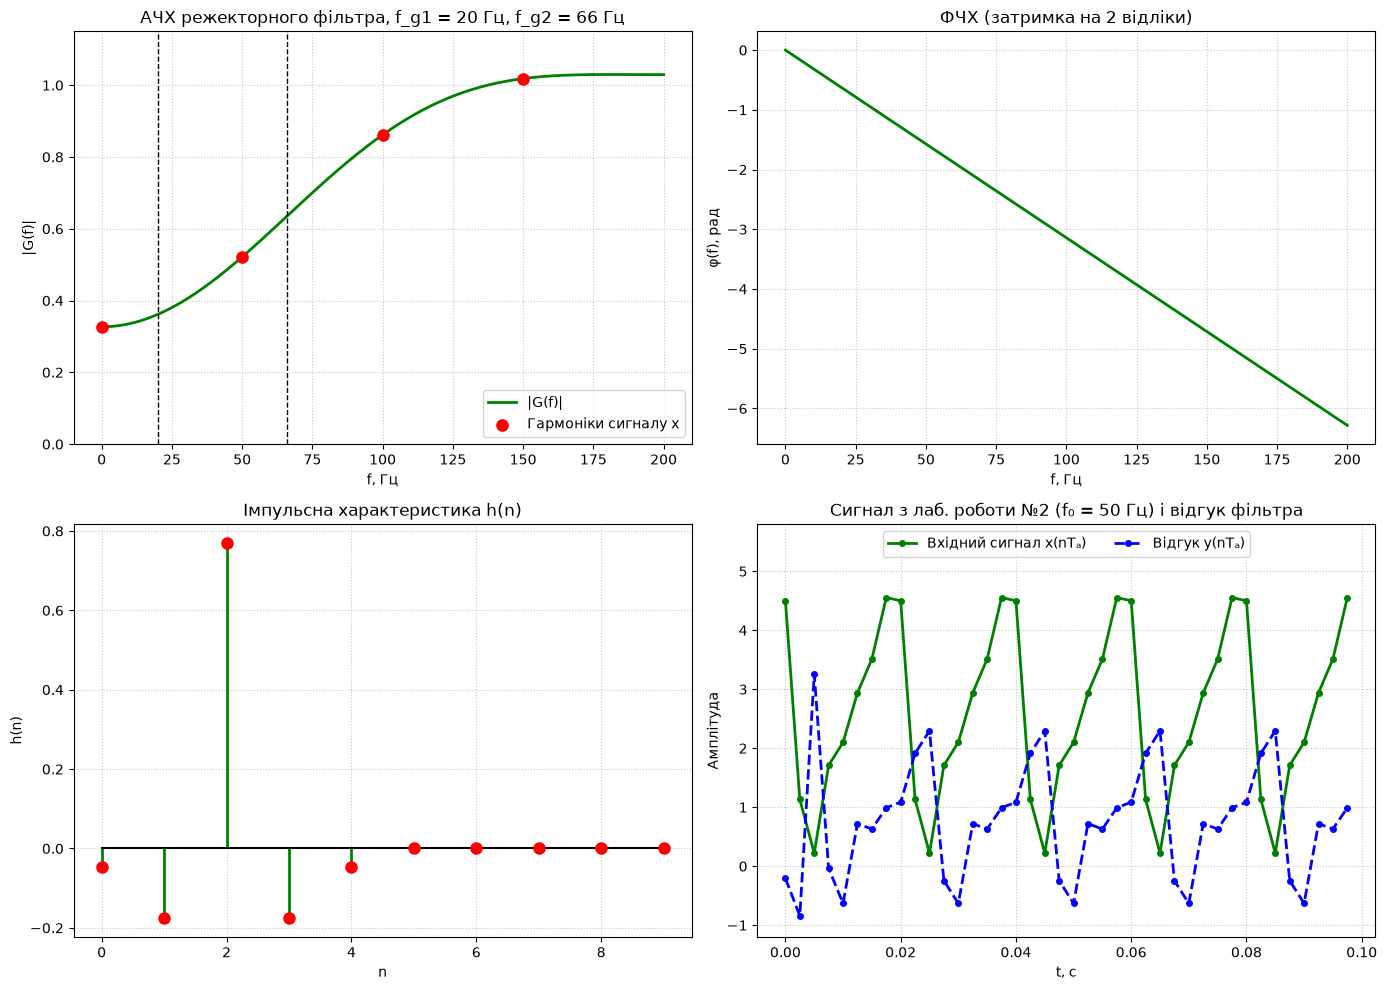

In [8]:
Path("figures").mkdir(exist_ok=True)
figure, axes = plt.subplots(2, 2, figsize=(14, 10))
amplitude_axis, phase_axis, impulse_axis, signal_axis = axes.flat

amplitude_axis.plot(frequency_grid, amplitude_response, color="green", linewidth=2, label="|G(f)|")
amplitude_axis.scatter(harmonic_frequencies, np.abs(harmonic_responses), color="red", s=65, zorder=5,
                       label="Гармоніки сигналу x")
for cutoff_frequency in [lower_cutoff_frequency, upper_cutoff_frequency]:
    amplitude_axis.axvline(cutoff_frequency, color="black", linestyle="--", linewidth=1)
amplitude_axis.set_title("АЧХ режекторного фільтра, f_g1 = 20 Гц, f_g2 = 66 Гц")
amplitude_axis.set_xlabel("f, Гц")
amplitude_axis.set_ylabel("|G(f)|")
amplitude_axis.set_ylim(0, 1.15)
amplitude_axis.legend()
amplitude_axis.grid(linestyle=":", alpha=0.7)

phase_axis.plot(frequency_grid, phase_response, color="green", linewidth=2)
phase_axis.set_title("ФЧХ (затримка на 2 відліки)")
phase_axis.set_xlabel("f, Гц")
phase_axis.set_ylabel("φ(f), рад")
phase_axis.grid(linestyle=":", alpha=0.7)

markers, stems, baseline = impulse_axis.stem(np.arange(impulse_length), impulse_response,
                                             linefmt="green", markerfmt="o", basefmt="black")
plt.setp(stems, linewidth=2)
plt.setp(markers, color="red", markersize=8, zorder=5)
impulse_axis.set_title("Імпульсна характеристика h(n)")
impulse_axis.set_xlabel("n")
impulse_axis.set_ylabel("h(n)")
impulse_axis.grid(linestyle=":", alpha=0.7)

signal_axis.plot(signal_times, input_signal, color="green", linewidth=2, marker="o", markersize=4,
                 label="Вхідний сигнал x(nTₐ)")
signal_axis.plot(signal_times, output_signal, "--", color="blue", linewidth=2, marker="o", markersize=4,
                 label="Відгук y(nTₐ)")
signal_axis.set_title("Сигнал з лаб. роботи №2 (f₀ = 50 Гц) і відгук фільтра")
signal_axis.set_xlabel("t, с")
signal_axis.set_ylabel("Амплітуда")
signal_axis.set_ylim(-1.2, 5.8)
signal_axis.legend(loc="upper center", ncol=2)
signal_axis.grid(linestyle=":", alpha=0.7)

plt.tight_layout()
plt.savefig("figures/bandstop_filter.png", dpi=180)
plt.show()

## Підсумок

Коефіцієнти фільтра, основні значення АЧХ і найбільша різниця між ручним розрахунком та бібліотекою.

In [9]:
largest_difference = max(coefficient_difference, response_difference, impulse_difference, output_difference)
print(f"Variant {variant_number}: band-stop filter N = {filter_order}, {lower_cutoff_frequency:.0f}"
      f"...{upper_cutoff_frequency:.0f} Hz, fa = {sampling_frequency:.0f} Hz")
print("Coefficients a(-2)...a(2):", np.round(bandstop, 6))
print(f"|G| at 0 Hz = {amplitude_response[0]:.4f}, minimum |G| = {amplitude_response[minimum_index]:.4f},"
      f" |G| at 200 Hz = {amplitude_response[-1]:.4f}")
print(f"Harmonic prediction of y: max error {steady_state_error:.1e}")
print(f"Largest |hand - library| difference: {largest_difference:.1e}")

Variant 23: band-stop filter N = 4, 20...66 Hz, fa = 400 Hz
Coefficients a(-2)...a(2): [-0.04592 -0.17562  0.77    -0.17562 -0.04592]
|G| at 0 Hz = 0.3269, minimum |G| = 0.3269, |G| at 200 Hz = 1.0294
Harmonic prediction of y: max error 8.5e-15
Largest |hand - library| difference: 1.0e-15
